## 1. Setup

# test 2 robot - Traffic Sign Detection with YOLOv8
SEE (YOLOv8 boxes) -> DECIDE (smoothed class -> command) -> ACT (serial to Arduino).

Run the cells top to bottom:

1. Setup -> 2. Crops (GTSRB) -> 3. Backgrounds -> 4. Build dataset -> 5. Train -> 6. Evaluate -> 7. Live camera (local only)

**Nothing to download by hand.** The traffic-sign dataset (GTSRB) is fetched by the notebook itself with `kagglehub`, straight onto the machine running it. Both Kaggle cells (GTSRB crops and MIT backgrounds) log in the same way: put your Kaggle `kaggle.json` (or new-style `access_token` file) next to the notebook or in `~/.kaggle/`, or set the `KAGGLE_API_TOKEN` environment variable.

**Training on a remote machine with no webcam?** Run everything except the live demo. Background cell A is optional (video upload), cell B (MIT) is enough to train. Take `best.pt` to your laptop or robot for the camera part.

The Kaggle dataset ([GTSRB - German Traffic Sign Recognition Benchmark](https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign)) is classification-only (cropped sign images, no boxes),
so boxes are generated by pasting crops onto background photos (your own camera frames plus a MIT Indoor Scenes subset). Cite the datasets in your documentation (GTSRB, the Tuan AI traffic-signs set for turn left/right, MIT Indoor Scenes).

In [ ]:
!pip install -q ultralytics opencv-python-headless pyserial matplotlib

In [ ]:
import csv, json, os, random, re, shutil, subprocess, sys, tarfile, time, urllib.request
from collections import deque
from pathlib import Path

import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt

CLASSES = ["turn_left", "turn_right", "stop", "go_ahead", "no_entry"]   # order = class id
CMD = {"turn_left": "L", "turn_right": "R", "stop": "S", "go_ahead": "F", "no_entry": "N"}
# L = turn left, R = turn right, S = stop, F = go ahead, N = no entry (do not enter / turn back)
ROOT = Path("dataset")
SPLITS = {"train": 0.7, "val": 0.2, "test": 0.1}

# use the NVIDIA GPU if available, otherwise CPU
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Using device:", torch.cuda.get_device_name(0) if DEVICE == 0 else DEVICE)


def open_camera(index=0):
    """Open the webcam. Windows needs DSHOW/MSMF; first frames are often black, so warm up."""
    backends = [cv2.CAP_DSHOW, cv2.CAP_MSMF] if sys.platform == "win32" else [cv2.CAP_ANY]
    for be in backends:
        cap = cv2.VideoCapture(index, be)
        if cap.isOpened():
            for _ in range(10):
                cap.read()
            return cap
        cap.release()
    raise RuntimeError(f"Camera {index} did not open - try index 1, or close other apps using it")


def kaggle_login():
    """Find Kaggle credentials (used by both Kaggle download cells).
    Looks in: KAGGLE_API_TOKEN env var -> access_token file -> legacy kaggle.json
    (each file is checked next to the notebook, one folder up, then ~/.kaggle/)."""
    if os.environ.get("KAGGLE_API_TOKEN"):
        print("using KAGGLE_API_TOKEN from the environment")
        return
    folders = (Path.cwd(), Path.cwd().parent, Path.home() / ".kaggle")
    for d in folders:
        tok = d / "access_token"
        if tok.exists():
            os.environ["KAGGLE_API_TOKEN"] = tok.read_text().strip()
            print("using API token from", tok.resolve())
            return
    for d in folders:
        kj = d / "kaggle.json"
        if kj.exists():
            creds = json.load(open(kj))
            os.environ["KAGGLE_USERNAME"] = creds["username"]
            os.environ["KAGGLE_KEY"] = creds["key"]
            print("using credentials from", kj.resolve())
            return
    print("WARNING: no Kaggle credentials found - put kaggle.json (or access_token) next to this notebook, cwd:", Path.cwd())

Using device: Tesla T4


## 2. Pick the 5 classes from GTSRB (downloaded in the notebook)
Downloads `meowmeowmeowmeowmeow/gtsrb-german-traffic-sign` with `kagglehub` onto the machine running the notebook (the remote, not your laptop), then copies only the 5 classes we need into `crops/`.
GTSRB class IDs are fixed by the benchmark, so they are set directly (and printed with their official names so you can check them):

| our class | GTSRB id | GTSRB name |
|---|---|---|
| `turn_left` | 34 | Turn left ahead |
| `turn_right` | 33 | Turn right ahead |
| `stop` | 14 | Stop |
| `go_ahead` | 35 | Ahead only |
| `no_entry` | 17 | No entry |

**Note:** Change the ids in `CLASS_IDS` to use other classes.
This cell deletes the old `crops/` and `dataset/` folders and rebuilds them (`backgrounds/` is not touched). Needs Kaggle credentials (same as the MIT cell); if the compute node has no internet, run this cell from the login node. The download is cached, and the cell skips itself if `crops/` is already filled (`fetch_gtsrb_crops(force=True)` rebuilds it).

In [ ]:
try:
    import kagglehub
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub

kaggle_login()
# os.environ["KAGGLEHUB_CACHE"] = "/path/with/space/kagglehub"   # optional, if home quota is small

IMG = {".jpg", ".jpeg", ".png", ".bmp", ".ppm", ".webp"}
root = Path.cwd()

# official GTSRB class ids -> names (only used to print a sanity check)
GTSRB_NAMES = {
    0: "Speed limit 20", 1: "Speed limit 30", 2: "Speed limit 50", 3: "Speed limit 60", 4: "Speed limit 70",
    5: "Speed limit 80", 6: "End of speed limit 80", 7: "Speed limit 100", 8: "Speed limit 120",
    9: "No passing", 10: "No passing for vehicles over 3.5t", 11: "Right-of-way at next intersection",
    12: "Priority road", 13: "Yield", 14: "Stop", 15: "No vehicles", 16: "Vehicles over 3.5t prohibited",
    17: "No entry", 18: "General caution", 19: "Dangerous curve left", 20: "Dangerous curve right",
    21: "Double curve", 22: "Bumpy road", 23: "Slippery road", 24: "Road narrows on the right",
    25: "Road work", 26: "Traffic signals", 27: "Pedestrians", 28: "Children crossing",
    29: "Bicycles crossing", 30: "Beware of ice/snow", 31: "Wild animals crossing",
    32: "End of all speed and passing limits", 33: "Turn right ahead", 34: "Turn left ahead",
    35: "Ahead only", 36: "Go straight or right", 37: "Go straight or left", 38: "Keep right",
    39: "Keep left", 40: "Roundabout mandatory", 41: "End of no passing",
    42: "End of no passing by vehicles over 3.5t",
}

# our class -> GTSRB class id
CLASS_IDS = {
    "turn_left":  34,
    "turn_right": 33,
    "stop":       14,
    "go_ahead":   35,
    "no_entry":   17,
}
assert list(CLASS_IDS) == CLASSES, "CLASS_IDS must be in the same order as CLASSES"


def fetch_gtsrb_crops(class_ids=CLASS_IDS, out_dir="crops", force=False):
    out = Path(out_dir)
    if not force and all(list((out / c).glob("*.*")) for c in class_ids):
        print("GTSRB crops already in", out, "- skipping (force=True to rebuild)")
        return
    shutil.rmtree(out, ignore_errors=True)

    # 1) download (cached by kagglehub) onto THIS machine
    try:
        src = Path(kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"))
    except Exception as e:
        raise RuntimeError(
            f"Kaggle download failed: {type(e).__name__}: {e}\n"
            "401/403 -> check your Kaggle credentials (see kaggle_login in the setup cell)\n"
            "connection/timeout -> compute node may have no internet; run this cell from the login node"
        ) from e
    print("dataset at:", src)

    # 2) find the per-class training folders (Train/<id>/...), ignoring Test/ and Meta/
    all_dirs = [d for d in src.rglob("*") if d.is_dir()]

    def class_dirs(cid):
        hits = []
        for d in all_dirs:
            if d.name.isdigit() and int(d.name) == cid:
                parents = [p.lower() for p in d.relative_to(src).parts[:-1]]
                if not any(p in ("test", "meta") for p in parents):
                    hits.append(d)
        return hits

    # 3) copy the classes into crops/<our_class>/
    for c, cid in class_ids.items():
        dirs = class_dirs(cid)
        if not dirs:
            top = sorted(p.name for p in src.iterdir())
            raise FileNotFoundError(f"No folder for class id {cid} under {src}. Top level: {top}")
        dst = out / c
        dst.mkdir(parents=True)
        seen, n = set(), 0
        for d in dirs:
            for f in d.rglob("*"):
                if f.is_file() and f.suffix.lower() in IMG and f.resolve() not in seen:
                    seen.add(f.resolve())
                    shutil.copy(f, dst / f"{cid}_{f.name}")
                    n += 1
        print(f"{c:12s} id {cid:2d} ({GTSRB_NAMES[cid]}): {n} images" + ("" if n >= 150 else "   <-- low"))


fetch_gtsrb_crops()

using credentials from /content/kaggle.json
GTSRB crops already in crops - skipping (force=True to rebuild)


### 2b. Extra crops from the Tuan AI dataset
Adds `tuanai/traffic-signs-dataset` crops **on top of** the GTSRB ones, matched by Tuan class id (files are prefixed `tuan_`):

| Tuan id | name | our class |
|---|---|---|
| 22 | Go Left | `turn_left` |
| 24 | Go Right | `turn_right` |
| 18 | No entry | `no_entry` |
| 21 | Go straight | `go_ahead` |

So these four classes train on both GTSRB and Tuan signs. `stop` stays GTSRB only. **Cite this dataset too.**

I could not inspect its folder layout, so folders are matched by id: a folder named `22`, `22_...` or `class_22` counts (left/right also match "Go Left" / "Go Right" by name; no_entry and go_ahead match by id only, so "Go straight or right" is never pulled in by mistake). The cell prints every image folder it found and what it matched, **check that list** and edit `TUAN_IDS` if the ids sit somewhere else (e.g. a CSV instead of folders).
A class that already has `tuan_*` crops is skipped, so only the new classes are added if you ran this cell before. Delete `crops/<class>/tuan_*` to redo one. Set `KEEP_GTSRB = False` to use only the Tuan signs for these classes. Run after the GTSRB cell and before building the dataset.

In [ ]:
TUAN_SLUG = "tuanai/traffic-signs-dataset"
TUAN_IDS = {                                                 # our class -> (Tuan id, name regex or None = match by id only)
    "turn_left":  (22, r"go[ _-]?left$"),
    "turn_right": (24, r"go[ _-]?right$"),
    "no_entry":   (18, None),
    "go_ahead":   (21, None),                                # "Go straight or right/left" must NOT match
}
KEEP_GTSRB = True        # True = Tuan crops are ADDED to the GTSRB ones
MAX_SIDE = 256           # shrink large images, the pasted signs are small anyway


def fetch_tuan_crops(ids=TUAN_IDS, out_dir="crops", keep_gtsrb=KEEP_GTSRB):
    out = Path(out_dir)
    todo = {c: v for c, v in ids.items() if not list((out / c).glob("tuan_*"))}
    for c in ids:
        if c not in todo:
            print(f"{c}: tuan crops already present - skipping (delete crops/{c}/tuan_* to redo)")
    if not todo:
        return
    try:
        src = Path(kagglehub.dataset_download(TUAN_SLUG))
    except Exception as e:
        raise RuntimeError(f"Kaggle download failed: {type(e).__name__}: {e}") from e
    print("dataset at:", src)

    # every folder that directly holds images
    img_dirs = {}
    for f in src.rglob("*"):
        if f.is_file() and f.suffix.lower() in IMG:
            img_dirs.setdefault(f.parent, []).append(f)
    print(f"{len(img_dirs)} image folders:", sorted(d.name for d in img_dirs)[:80])
    assert img_dirs, f"no images under {src} - look at the folder structure"

    for c, (cid, name_pat) in todo.items():
        id_pat = rf"(^|\D)0*{cid}(\D|$)"          # 22, 22_x, class_22 ... but not 122 / 224
        hits = [d for d in img_dirs
                if re.search(id_pat, d.name) or (name_pat and re.search(name_pat, d.name, re.I))]
        print(f"{c} (id {cid}): matched folders -> {[d.name for d in hits] or 'NONE (edit TUAN_IDS)'}")
        if not hits:
            continue
        if not keep_gtsrb:
            for f in (out / c).glob("*.*"):
                if not f.name.startswith("tuan_"):
                    f.unlink()
        n = 0
        for d in hits:
            for f in img_dirs[d]:
                im = cv2.imread(str(f))
                if im is None:
                    continue
                s = MAX_SIDE / max(im.shape[:2])
                if s < 1:
                    im = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
                # name = <id>_<unique>_0 so the by-sign split treats each image as its own group
                cv2.imwrite(str(out / c / f"tuan_{n:05d}_0.png"), im)
                n += 1
        print(f"  {c}: {n} tuan crops added")


fetch_tuan_crops()
for c in CLASSES:
    n_t = len(list(Path("crops", c).glob("tuan_*")))
    print(f"{c:12s} {len(list(Path('crops', c).glob('*.*')))} crops ({n_t} from tuan)")

100%|██████████| 232M/232M [00:03<00:00, 78.4MB/s]

Extracting files...


dataset at: /root/.cache/kagglehub/datasets/tuanai/traffic-signs-dataset/versions/1
104 image folders: ['0', '0', '1', '1', '10', '10', '11', '11', '12', '12', '13', '13', '14', '14', '15', '15', '16', '16', '17', '17', '18', '18', '19', '19', '2', '2', '20', '20', '21', '21', '22', '22', '23', '23', '24', '24', '25', '25', '26', '26', '27', '27', '28', '28', '29', '29', '3', '3', '30', '30', '31', '31', '32', '32', '33', '33', '34', '34', '35', '35', '36', '36', '37', '37', '38', '38', '39', '39', '4', '4', '40', '40', '41', '41', '42', '42', '43', '43', '44', '44']
turn_left (id 22): matched folders -> ['22', '22']
  turn_left: 36 tuan crops added
turn_right (id 24): matched folders -> ['24', '24']
  turn_right: 118 tuan crops added
no_entry (id 18): matched folders -> ['18', '18']
  no_entry: 220 tuan crops added
go_ahead (id 21): matched folders -> ['21', '21']
  go_ahead: 36 tuan crops added
turn_left    456 crops (36 from tuan)
turn_right   807 crops (118 from tuan)
stop         

### 2c. Distractor signs ("not one of my 5")
Without this the model has nothing to say for other signs, so a pedestrian or speed-limit sign gets read as `turn_left` etc. This cell copies **other GTSRB signs** (speed limits, no passing, yield, priority road, no vehicles, warning triangles) into `crops_other/`. The dataset builder pastes them onto some images **without a label**, so the model learns to ignore them.

Deliberately left out: the 5 real classes and the blue arrow signs (33-40: go straight/left/right, keep left/right, roundabout), because they look too close to your classes. Run after the GTSRB cell.

In [ ]:
DISTRACTOR_IDS = [0, 1, 2, 3, 4, 5, 7, 8, 9, 10, 11, 12, 13, 15, 16] + list(range(18, 32))   # GTSRB ids, never the 5 classes
PER_CLASS = 120          # images copied per distractor id


def fetch_distractors(ids=DISTRACTOR_IDS, out_dir="crops_other", per_class=PER_CLASS, force=False):
    out = Path(out_dir)
    if not force and list(out.glob("*.*")):
        print("distractors already in", out, "- skipping (force=True to rebuild)")
        return
    assert not set(ids) & set(CLASS_IDS.values()), "a distractor id is one of your 5 classes"
    shutil.rmtree(out, ignore_errors=True)
    out.mkdir(parents=True)
    src = Path(kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"))   # cached, no new download
    rng = random.Random(0)
    total = 0
    for cid in ids:
        files = []
        for d in src.rglob("*"):
            if d.is_dir() and d.name.isdigit() and int(d.name) == cid:
                parents = [p.lower() for p in d.relative_to(src).parts[:-1]]
                if not any(p in ("test", "meta") for p in parents):
                    files += [f for f in d.rglob("*") if f.is_file() and f.suffix.lower() in IMG]
        rng.shuffle(files)
        for f in files[:per_class]:
            shutil.copy(f, out / f"{cid}_{f.name}")          # <id>_<track>_<frame> so the split is by sign
        total += min(len(files), per_class)
    print(f"{total} distractor images from {len(ids)} GTSRB classes in {out}")


fetch_distractors()

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
3480 distractor images from 29 GTSRB classes in crops_other


### Background photos
Backgrounds come from two sources. **Use both** (you need at least 50 in total, 100+ is better):

- **A. Your own camera** (best, optional): frames from a video of your real test area with no signs in view. No webcam needed, just upload a video.
- **B. MIT Indoor Scenes** (supplement): a few hundred indoor photos (Quattoni & Torralba, CVPR 2009). **Cite it in your documentation.**

Files are named `cam_*.jpg` and `mit_*.jpg` so the dataset cell can split each source separately.
Both cells can be skipped if `backgrounds/` already has enough photos. Both cells run fine on a remote machine.

**A. (Optional) Extract frames from a video.**
Record 1-2 minutes of your track or room with no signs in view (phone or robot camera), upload it next to the notebook, and set `VIDEO`.
If the file isn't there, this cell just skips, so you can train on MIT backgrounds alone.

In [ ]:
VIDEO = "bg_video.mp4"      # your uploaded video (optional)
EVERY_SEC = 0.5

BG = Path("backgrounds")
BG.mkdir(exist_ok=True)

if len(list(BG.glob("cam_*.jpg"))) >= 30:
    print("camera backgrounds already in backgrounds/ - skipping")
elif not Path(VIDEO).exists():
    print(f"{VIDEO} not found - skipping (training on MIT backgrounds only)")
else:
    cap = cv2.VideoCapture(VIDEO)
    assert cap.isOpened(), f"Could not open {VIDEO}"
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    step = max(1, int(fps * EVERY_SEC))
    i = saved = 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if i % step == 0:
            cv2.imwrite(str(BG / f"cam_{saved:03d}.jpg"), cv2.resize(frame, (640, 480)))
            saved += 1
        i += 1
    cap.release()
    print(saved, "camera backgrounds saved")

bg_video.mp4 not found - skipping (training on MIT backgrounds only)


**B. Get MIT Indoor Scenes backgrounds from the Kaggle copy.**
Downloads `itsahmad/indoor-scenes-cvpr-2019` with `kagglehub` onto the machine running the notebook (the remote/HPC, not your laptop), then keeps only `PER_CAT` photos from each category in `MIT_CATS`, resized to 640x480.
Needs Kaggle credentials (`~/.kaggle/kaggle.json`, or set `KAGGLE_USERNAME` / `KAGGLE_KEY` in the cell). If the compute node has no internet, run this cell from the login node.
Category names are matched ignoring case/underscores. If some are not found, edit `MIT_CATS` using the printed `folders found` list. **Cite MIT Indoor Scenes (Quattoni & Torralba) and the Kaggle upload in your documentation.**

In [ ]:
import importlib, subprocess, sys, os, re, random
from pathlib import Path
import cv2

# 1) install kagglehub into THIS kernel's environment
try:
    import kagglehub
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub

# 2) credentials (shared helper from the setup cell)
kaggle_login()
# os.environ["KAGGLEHUB_CACHE"] = "/path/with/space/kagglehub"   # optional, if home quota is small

MIT_CATS = ["corridor", "classroom", "bedroom", "livingroom", "garage",
            "office", "kitchen", "meeting_room", "lobby", "stairscase"]
PER_CAT = 20
EXTS = {".jpg", ".jpeg", ".png", ".bmp"}


def norm(s):
    return re.sub(r"[^a-z0-9]", "", s.lower())      # "Living_Room" -> "livingroom"


def fetch_mit_backgrounds(cats=MIT_CATS, per_cat=PER_CAT, out_dir="backgrounds"):
    out = Path(out_dir)
    out.mkdir(exist_ok=True)
    if len(list(out.glob("mit_*.jpg"))) >= per_cat * len(cats) // 2:
        print("MIT backgrounds already in", out, "- skipping")
        return

    try:
        src = Path(kagglehub.dataset_download("itsahmad/indoor-scenes-cvpr-2019"))
    except Exception as e:
        raise RuntimeError(
            f"Kaggle download failed: {type(e).__name__}: {e}\n"
            "401/403 -> check KAGGLE_USERNAME/KAGGLE_KEY or ~/.kaggle/kaggle.json\n"
            "connection/timeout -> compute node may have no internet; run this cell from the login node"
        ) from e
    print("dataset at:", src)

    # group images by their parent folder name (= scene category)
    by_cat = {}
    for p in src.rglob("*"):
        if p.is_file() and p.suffix.lower() in EXTS:
            by_cat.setdefault(norm(p.parent.name), []).append(p)
    print(f"{sum(len(v) for v in by_cat.values())} images in {len(by_cat)} folders")
    print("folders found:", sorted(by_cat)[:80])
    assert by_cat, f"No images found under {src} - look at the folder structure manually"

    wanted = {c: norm(c) for c in cats}
    hit = {c: k for c, k in wanted.items() if k in by_cat}
    miss = [c for c in cats if c not in hit]
    if miss:
        print("not found (edit MIT_CATS to match 'folders found' above):", miss)
    if not hit:                                   # nothing matched: fall back to random folders
        print("No MIT_CATS matched - sampling from the folders that do exist")
        picks = random.sample(sorted(by_cat), k=min(10, len(by_cat)))
        hit = {k: k for k in picks}

    count = {}
    for c, k in hit.items():
        files = by_cat[k][:]
        random.shuffle(files)
        n = 0
        for p in files:
            if n >= per_cat:
                break
            im = cv2.imread(str(p))
            if im is None:
                continue
            cv2.imwrite(str(out / f"mit_{c}_{n:03d}.jpg"), cv2.resize(im, (640, 480)))
            n += 1
        count[c] = n
    print(count)
    print(len(list(out.glob("mit_*.jpg"))), "MIT backgrounds saved")


fetch_mit_backgrounds()

using credentials from /content/kaggle.json


100%|██████████| 2.34G/2.34G [00:26<00:00, 93.2MB/s]

Extracting files...


dataset at: /root/.cache/kagglehub/datasets/itsahmad/indoor-scenes-cvpr-2019/versions/1
15620 images in 67 folders
folders found: ['airportinside', 'artstudio', 'auditorium', 'bakery', 'bar', 'bathroom', 'bedroom', 'bookstore', 'bowling', 'buffet', 'casino', 'childrenroom', 'churchinside', 'classroom', 'cloister', 'closet', 'clothingstore', 'computerroom', 'concerthall', 'corridor', 'deli', 'dentaloffice', 'diningroom', 'elevator', 'fastfoodrestaurant', 'florist', 'gameroom', 'garage', 'greenhouse', 'grocerystore', 'gym', 'hairsalon', 'hospitalroom', 'insidebus', 'insidesubway', 'jewelleryshop', 'kindergarden', 'kitchen', 'laboratorywet', 'laundromat', 'library', 'livingroom', 'lobby', 'lockerroom', 'mall', 'meetingroom', 'movietheater', 'museum', 'nursery', 'office', 'operatingroom', 'pantry', 'poolinside', 'prisoncell', 'restaurant', 'restaurantkitchen', 'shoeshop', 'stairscase', 'studiomusic', 'subway', 'toystore', 'trainstation', 'tvstudio', 'videostore', 'waitingroom', 'warehouse'

**C. Remove backgrounds that contain real signs.**
A real traffic sign in a "background" teaches the model that signs are not signs.
This runs the standard COCO model over the `mit_*` photos and deletes any with a stop sign or traffic light.
Then look at the contact sheet and delete anything else suspicious by hand (a sign, poster with a sign, or a screen showing one).
Your own `cam_*` photos are never touched.

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
removed 1 of 200 MIT photos with a sign or traffic light


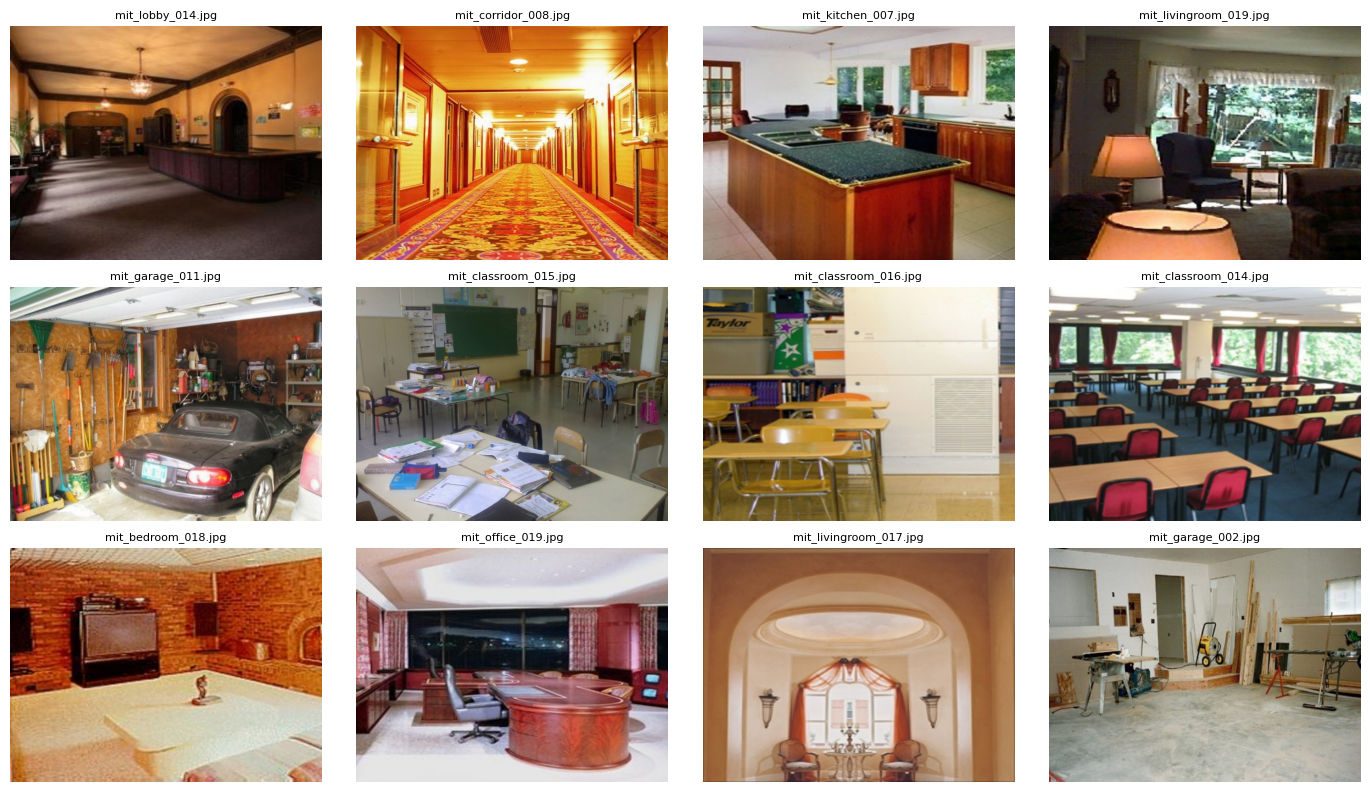

In [ ]:
from ultralytics import YOLO

coco = YOLO("yolov8n.pt")            # COCO: 9 = traffic light, 11 = stop sign
mit = sorted(Path("backgrounds").glob("mit_*.jpg"))
removed = 0
for p in mit:
    r = coco.predict(str(p), conf=0.25, classes=[9, 11], device=DEVICE, verbose=False)[0]
    if len(r.boxes):
        p.unlink()
        removed += 1
print(f"removed {removed} of {len(mit)} MIT photos with a sign or traffic light")

shown = random.sample(sorted(Path("backgrounds").glob("*.jpg")), k=min(12, len(list(Path("backgrounds").glob("*.jpg")))))
fig, axes = plt.subplots(3, 4, figsize=(14, 8))
for ax in axes.flat:
    ax.axis("off")
for ax, p in zip(axes.flat, shown):
    ax.imshow(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB))
    ax.set_title(p.name, fontsize=8)
plt.tight_layout()
plt.show()

## 3. Build the dataset (synthetic boxes)
Pastes sign crops onto background photos and writes YOLO labels automatically.
Crops and backgrounds are split **before** generation (each background source separately), so no train/test leakage and your own camera frames also appear in the test split.
GTSRB contains ~30 near-identical frames of each physical sign, so the crops are split **by sign (track), not by single image**. Otherwise the same sign would show up in both train and test.
About half of the images also get 1-3 **unlabelled distractor signs** (other GTSRB signs from cell 2c) so other signs are ignored instead of being forced into one of your 5 classes. About 10% of the images contain **no sign** (empty label file) so the model learns what "nothing" looks like and gives fewer false detections.

In [ ]:
def split_files(files, by_track=False):
    files = list(files)
    if by_track:
        # GTSRB crops are named <id>_<track>_<frame>.png - keep all frames of one physical sign together
        groups = {}
        for f in files:
            groups.setdefault(f.stem.rsplit("_", 1)[0], []).append(f)
        keys = sorted(groups)
        random.shuffle(keys)
        n = len(keys)
        a, b = int(n * 0.7), int(n * 0.9)
        parts = {"train": keys[:a], "val": keys[a:b], "test": keys[b:]}
        return {sp: [f for k in ks for f in groups[k]] for sp, ks in parts.items()}
    random.shuffle(files)
    n = len(files)
    a, b = int(n * 0.7), int(n * 0.9)
    return {"train": files[:a], "val": files[a:b], "test": files[b:]}


def split_backgrounds(bgs):
    # split each source (cam_ / mit_) on its own so your own camera frames land in train, val AND test
    out = {"train": [], "val": [], "test": []}
    for prefix in ("cam_", "mit_"):
        part = split_files(p for p in bgs if p.name.startswith(prefix))
        for sp in out:
            out[sp] += part[sp]
    other = split_files(p for p in bgs if not p.name.startswith(("cam_", "mit_")))
    for sp in out:
        out[sp] += other[sp]
    return out


def paste(bg, crop, rects):
    # paste crop at a random non-overlapping spot; return normalized YOLO box or None
    H, W = bg.shape[:2]
    for _ in range(10):
        w = int(W * random.uniform(0.08, 0.30))
        h = int(w * crop.shape[0] / crop.shape[1])
        if h < 8 or h >= H or w >= W:
            continue
        x, y = random.randint(0, W - w), random.randint(0, H - h)
        if any(x < rx + rw and rx < x + w and y < ry + rh and ry < y + h
               for rx, ry, rw, rh in rects):
            continue
        c = cv2.resize(crop, (w, h))
        c = cv2.convertScaleAbs(c, alpha=random.uniform(0.6, 1.3),
                                beta=random.uniform(-30, 30))
        if random.random() < 0.3:
            c = cv2.GaussianBlur(c, (5, 5), 0)
        bg[y:y + h, x:x + w] = c
        rects.append((x, y, w, h))
        return (x + w / 2) / W, (y + h / 2) / H, w / W, h / H
    return None


def synth(crops_dir="crops", bg_dir="backgrounds", n=1500, neg_frac=0.1,
          other_dir="crops_other", distract_frac=0.5):
    random.seed(0)
    crops = {c: sorted((Path(crops_dir) / c).glob("*.*")) for c in CLASSES}
    for c, f in crops.items():
        if not f:
            sys.exit(f"No images in {crops_dir}/{c} - run the crops cell first")
    bgs = sorted(Path(bg_dir).glob("*.*"))
    bg_split = split_backgrounds(bgs)
    crop_split = {c: split_files(f, by_track=True) for c, f in crops.items()}
    other = sorted(Path(other_dir).glob("*.*"))
    other_split = split_files(other, by_track=True) if other else None      # distractors: split by sign too
    if not other:
        print("WARNING: no distractor signs in", other_dir, "- run the distractor cell (2c)")

    for sp, ratio in SPLITS.items():
        if not bg_split[sp]:
            sys.exit("Need more background photos (50+).")
        (ROOT / "images" / sp).mkdir(parents=True, exist_ok=True)
        (ROOT / "labels" / sp).mkdir(parents=True, exist_ok=True)
        for i in range(int(n * ratio)):
            bg = cv2.imread(str(random.choice(bg_split[sp])))
            if bg is None:
                continue
            bg = cv2.resize(bg, (640, 480))
            rects, lines = [], []
            n_signs = 0 if random.random() < neg_frac else random.choice([1, 1, 2])
            for _ in range(n_signs):
                cid = random.randrange(len(CLASSES))
                pool = crop_split[CLASSES[cid]][sp]
                if not pool:
                    continue
                crop = cv2.imread(str(random.choice(pool)))
                if crop is None:
                    continue
                box = paste(bg, crop, rects)
                if box:
                    lines.append(f"{cid} " + " ".join(f"{v:.6f}" for v in box))
            if n_signs and not lines:
                continue
            # distractor signs: pasted but NOT labelled, so the model learns to ignore other signs
            if other_split and other_split[sp] and random.random() < distract_frac:
                for _ in range(random.choice([1, 1, 2, 3])):
                    d = cv2.imread(str(random.choice(other_split[sp])))
                    if d is not None:
                        paste(bg, d, rects)
            cv2.imwrite(str(ROOT / "images" / sp / f"{i:05d}.jpg"), bg)
            (ROOT / "labels" / sp / f"{i:05d}.txt").write_text("\n".join(lines))

    names_yaml = "\n".join(f"  {i}: {c}" for i, c in enumerate(CLASSES))
    (ROOT / "data.yaml").write_text(
        f"path: {ROOT.resolve().as_posix()}\ntrain: images/train\nval: images/val\n"
        f"test: images/test\nnames:\n{names_yaml}\n")
    print("Done. Dataset in", ROOT.resolve())

In [ ]:
n_cam = len(list(Path("backgrounds").glob("cam_*.jpg")))
n_mit = len(list(Path("backgrounds").glob("mit_*.jpg")))
print(f"backgrounds: {n_cam} camera + {n_mit} MIT")
assert n_cam + n_mit >= 50, "Need 50+ background photos - run the background cells (A and/or B)"
shutil.rmtree(ROOT, ignore_errors=True)
synth()
print("distractor crops:", len(list(Path("crops_other").glob("*.*"))))
for sp in SPLITS:
    print(sp, len(list((ROOT / "images" / sp).glob("*.jpg"))), "images")

backgrounds: 0 camera + 199 MIT
Done. Dataset in /content/dataset
distractor crops: 3297
train 1050 images
val 300 images
test 150 images


### Sanity check: verify the boxes look right

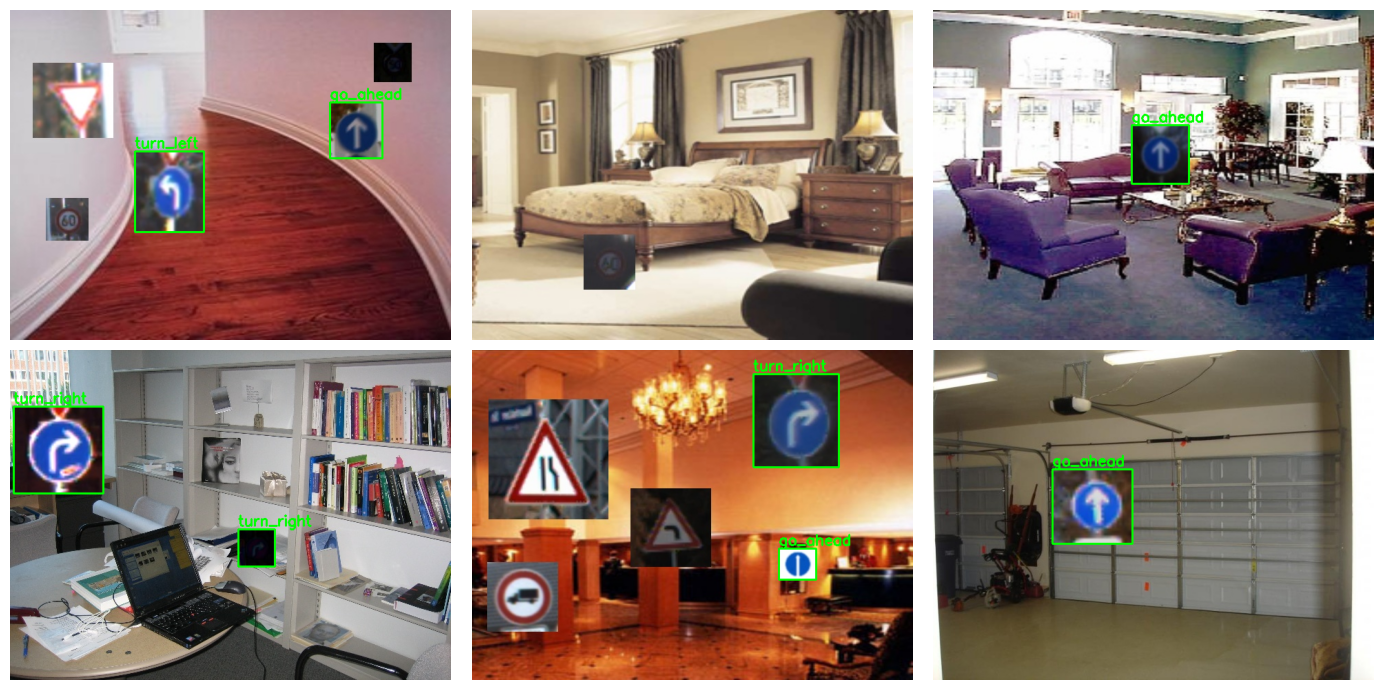

In [ ]:
imgs = sorted((ROOT / "images" / "train").glob("*.jpg"))[:6]
assert imgs, "No generated images - run the dataset cell first"

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax in axes.flat:
    ax.axis("off")
for ax, p in zip(axes.flat, imgs):
    im = cv2.imread(str(p))
    H, W = im.shape[:2]
    for line in (ROOT / "labels" / "train" / f"{p.stem}.txt").read_text().splitlines():
        cid, cx, cy, w, h = line.split()
        cid = int(cid)
        cx, cy, w, h = float(cx) * W, float(cy) * H, float(w) * W, float(h) * H
        p1 = int(cx - w / 2), int(cy - h / 2)
        p2 = int(cx + w / 2), int(cy + h / 2)
        cv2.rectangle(im, p1, p2, (0, 255, 0), 2)
        cv2.putText(im, CLASSES[cid], (p1[0], max(p1[1] - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
plt.tight_layout()
plt.show()

## 4. Train
`fliplr=0` is important: flipping turns left into right.
`EPOCHS = 30` is enough for a first test. On CPU this can take a while; raise it later for the final run.

In [ ]:
from ultralytics import YOLO

EPOCHS = 30
assert (ROOT / "data.yaml").exists(), "Run the dataset cell first"

model = YOLO("yolov8n.pt")
model.train(
    data=str((ROOT / "data.yaml").resolve()),
    epochs=EPOCHS,
    imgsz=640,
    fliplr=0.0,
    device=DEVICE,
    project=str(Path("runs").resolve()),
    name="signs",
    exist_ok=True,
)

Ultralytics 8.4.171 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=signs, nbs=64, nms=None, opset=None, optimize=False, optimizer=

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b3f94d73000>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

In [ ]:
def find_weights():
    found = list(Path("runs").rglob("best.pt"))
    if not found:
        raise FileNotFoundError("No best.pt under runs/ - train first")
    return str(max(found, key=lambda p: p.stat().st_mtime))


WEIGHTS = find_weights()
print("Using weights:", WEIGHTS)

shutil.copy(WEIGHTS, "best.pt")
print("Copied to best.pt - download this one file")

Using weights: runs/signs/weights/best.pt
Copied to best.pt - download this one file


## 5. Evaluate on the test split
Prints mAP, precision, recall and saves `confusion_matrix.png` in the run folder.

Ultralytics 8.4.171 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,623 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2070.1±752.9 MB/s, size: 95.8 KB)
val: Scanning /content/dataset/labels/test... 150 images, 18 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 2.0Kit/s 0.1s
val: New cache created: /content/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 3.9it/s 2.6s
                   all        150        176      0.998          1      0.995      0.994
             turn_left         35         37      0.998          1      0.995      0.993
            turn_right         38         39      0.998          1      0.995      0.995
                  stop         30         31      0.999          1      0.995      0.995
              go_ahead         32         33      0.998          1      0.995      0.

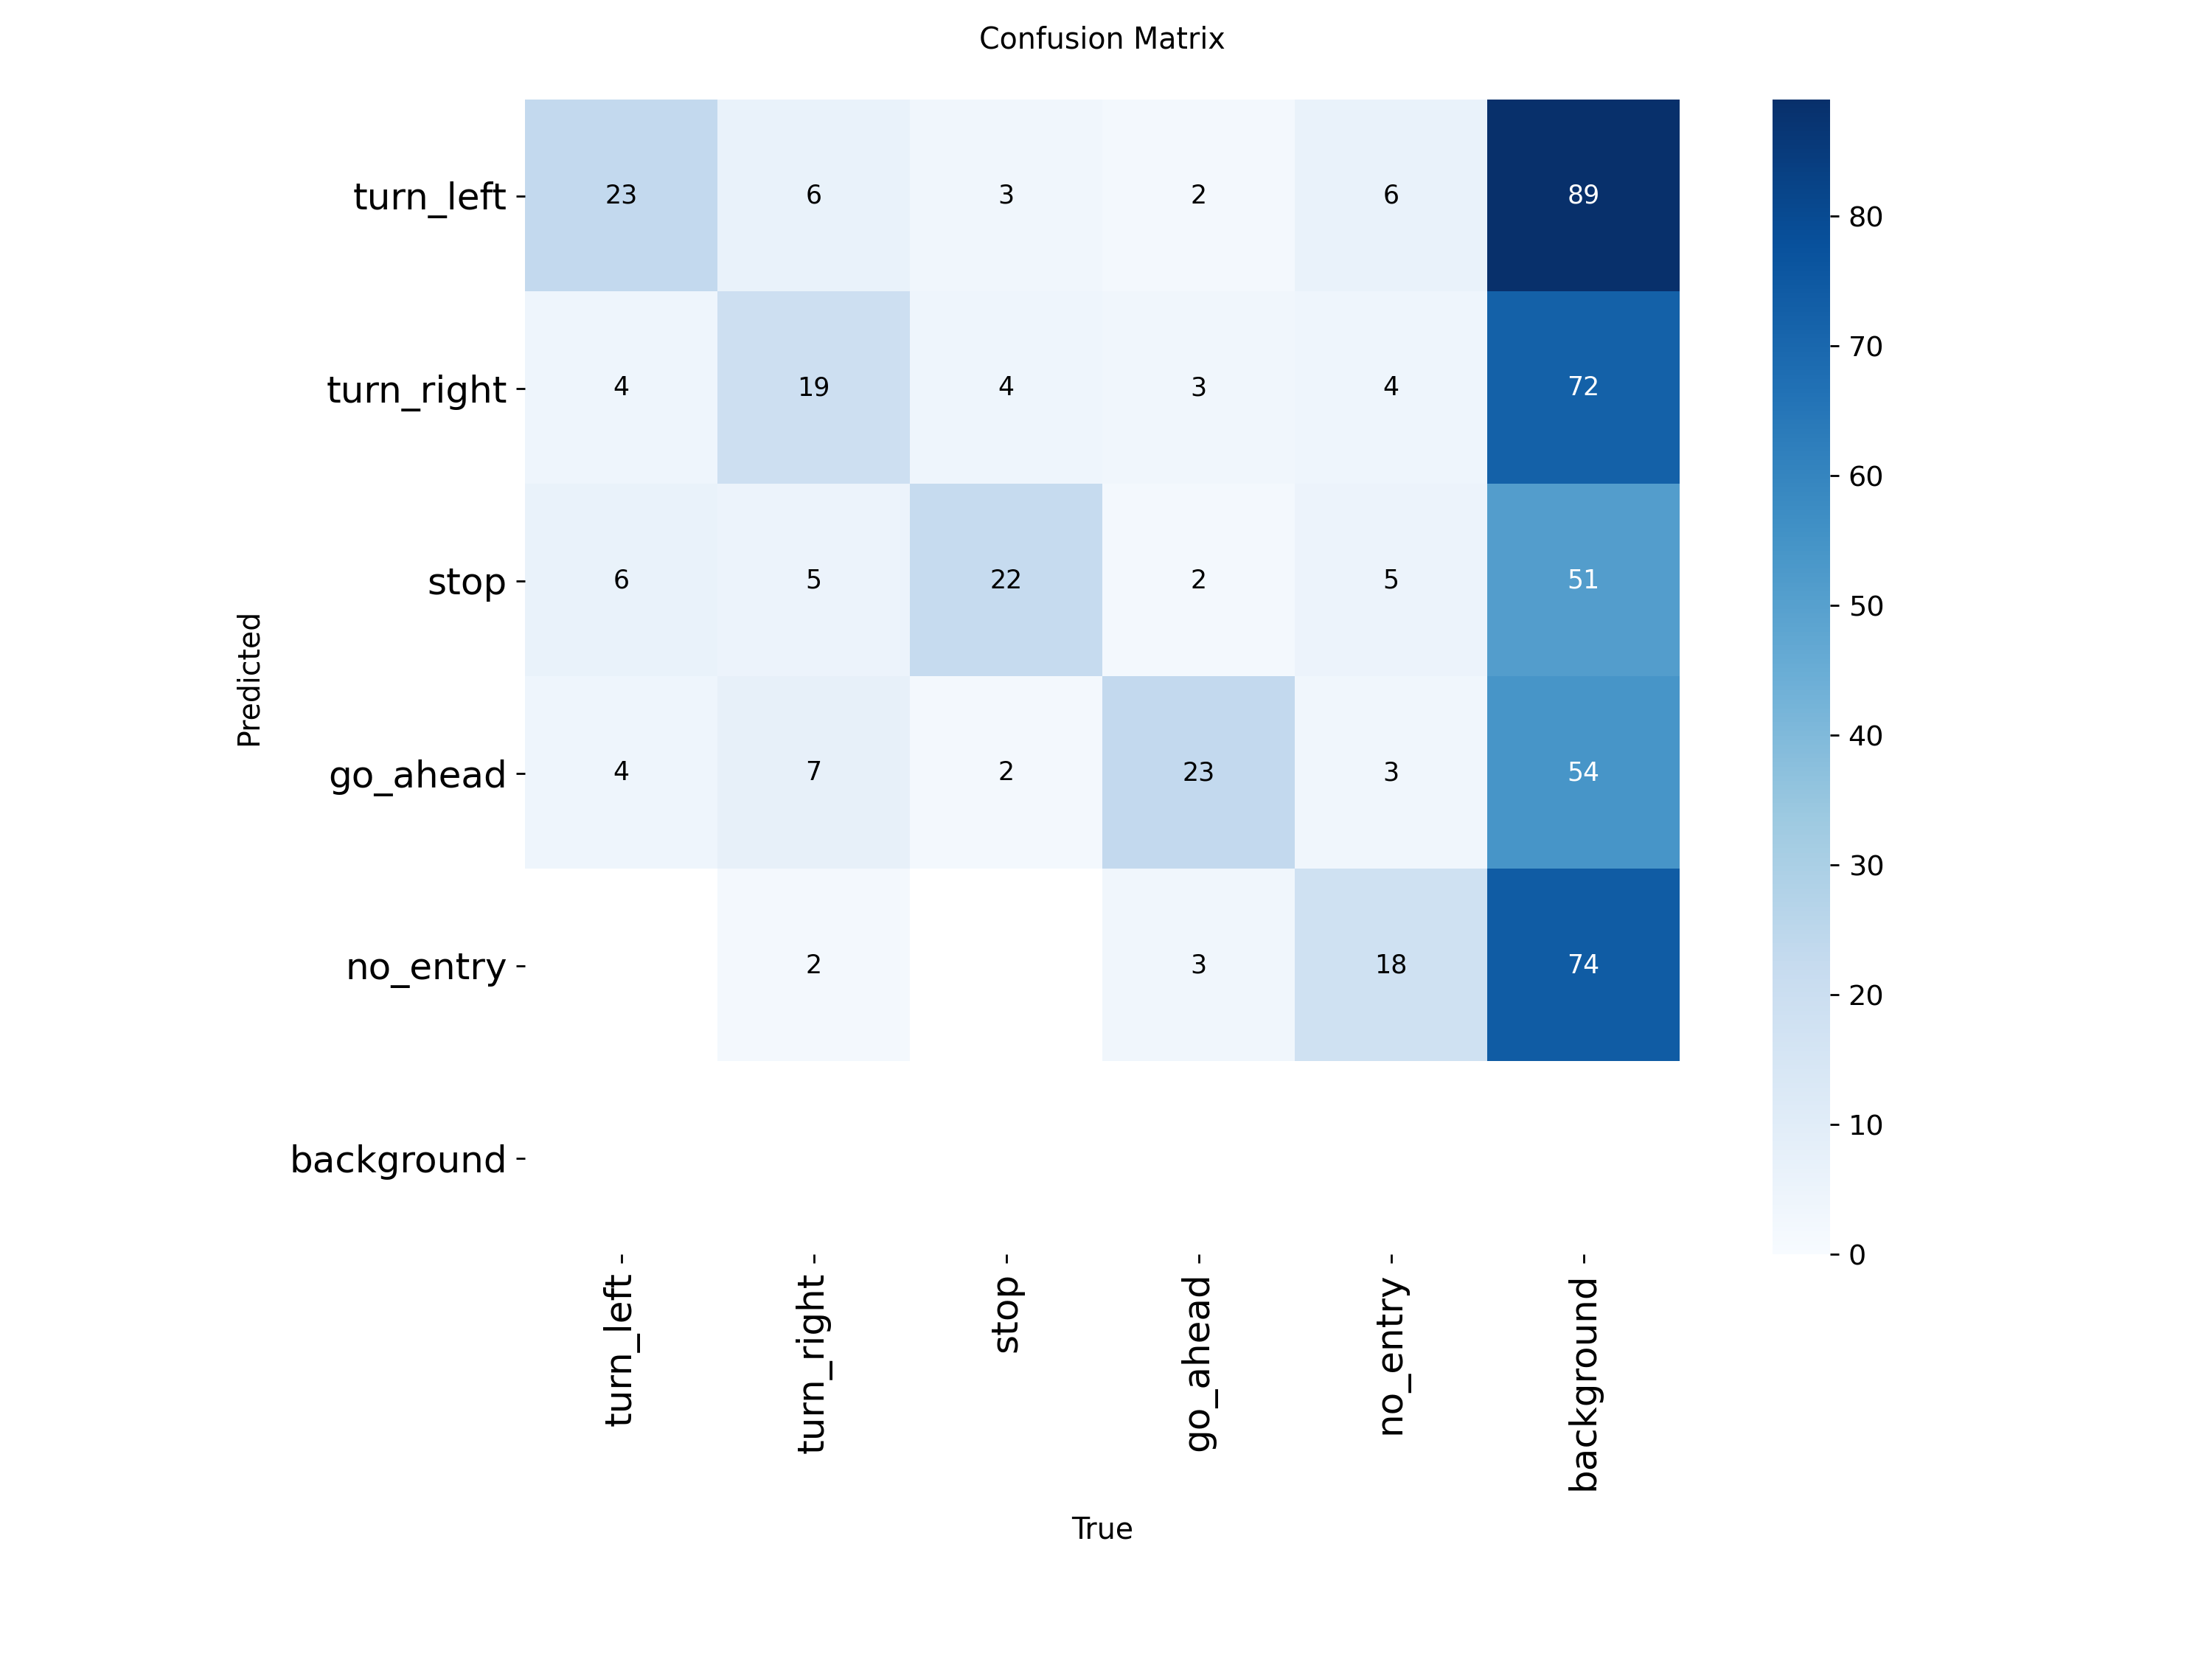

In [ ]:
from IPython.display import Image, display

best = YOLO(WEIGHTS)
r = best.val(data=str((ROOT / "data.yaml").resolve()), split="test", plots=True, device=DEVICE)
print(f"mAP50: {r.box.map50:.3f} | mAP50-95: {r.box.map:.3f} | "
      f"precision: {r.box.mp:.3f} | recall: {r.box.mr:.3f}")
print("Saved in:", r.save_dir)

cm = Path(r.save_dir) / "confusion_matrix.png"
if cm.exists():
    display(Image(filename=str(cm)))

### Predict on test images (boxes + confidence)

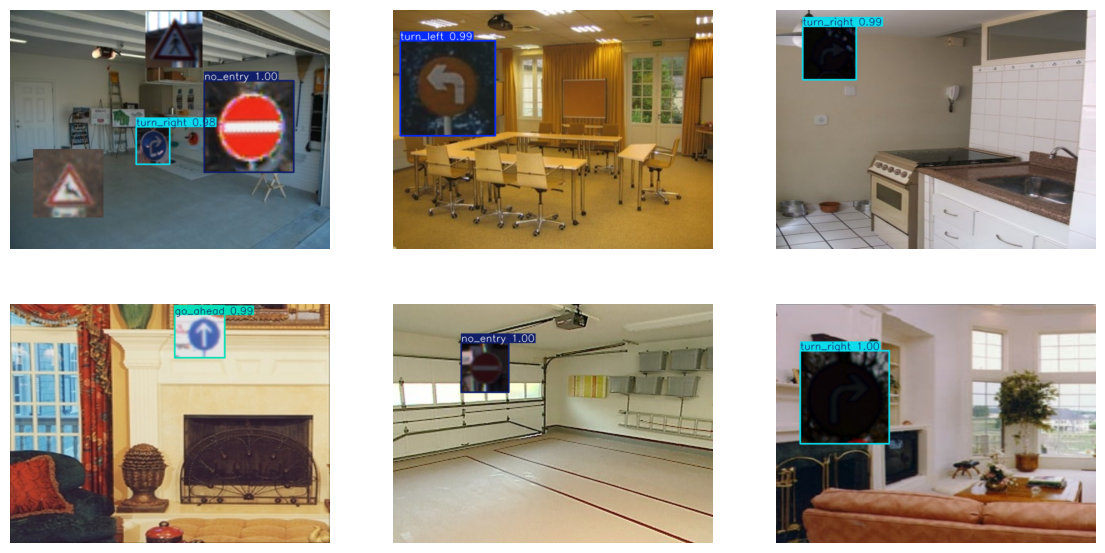

In [ ]:
test_imgs = sorted((ROOT / "images" / "test").glob("*.jpg"))[:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax in axes.flat:
    ax.axis("off")
for ax, p in zip(axes.flat, test_imgs):
    res = best.predict(str(p), conf=0.5, device=DEVICE, verbose=False)[0]
    ax.imshow(cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB))
plt.show()

## 6. Live demo + decision logic (SEE -> DECIDE -> ACT)
- Acts on the largest (closest) sign.
- A command is sent only if the same class is seen for `SMOOTH` consecutive frames at confidence >= `CONF`.
- Once no sign has been seen for `SMOOTH` frames, the same sign can trigger again.
- Keys: `q` quit, `x` emergency stop (toggle). The camera is always released, even if something crashes.
- `PORT = None` just prints commands. Set it (e.g. `"COM3"` or `"/dev/ttyUSB0"`) to send them to the Arduino.
- Hold up a printed sign or a phone screen. Do not mirror the image: flipping swaps left and right.
- **Skip this section on a remote/headless machine.** Needs a local Jupyter (opens a webcam window). It will not work in Colab. If the window freezes on Mac, run the same code as a `.py` file.

In [ ]:
CONF, SMOOTH, CAM, PORT = 0.6, 4, 0, None


def live(weights=None, cam=CAM, port=PORT, conf=CONF, smooth=SMOOTH):
    model = YOLO(weights or find_weights())
    ser = None
    if port:
        import serial
        ser = serial.Serial(port, 115200, timeout=0.1)

    def send(c):
        print("CMD", c)
        if ser:
            ser.write(c.encode())

    cap = open_camera(cam)
    hist = deque(maxlen=smooth)
    last, estop = None, False

    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            r = model.predict(frame, conf=conf, device=DEVICE, verbose=False)[0]
            label = None
            if len(r.boxes):
                b = max(r.boxes, key=lambda b: float(b.xywh[0][2] * b.xywh[0][3]))
                label = model.names[int(b.cls[0])]
            hist.append(label)

            if len(hist) == hist.maxlen:
                if not estop and hist[0] in CMD and len(set(hist)) == 1:
                    cmd = CMD[hist[0]]
                    if cmd != last:
                        send(cmd)
                        last = cmd
                elif all(h is None for h in hist):
                    last = None   # sign gone -> the next sign can trigger again

            out = r.plot()
            cv2.putText(out, f"cmd: {'ESTOP' if estop else last}", (10, 30),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 255), 2)
            cv2.imshow("signs (q quit, x estop)", out)

            k = cv2.waitKey(1) & 0xFF
            if k == ord("x"):
                estop = not estop
                if estop:
                    send("S")
                    last = "S"
            elif k == ord("q"):
                break
    finally:
        send("S")
        cap.release()
        cv2.destroyAllWindows()
        cv2.waitKey(1)
        if ser:
            ser.close()

In [ ]:
# LOCAL ONLY (needs a webcam). Uncomment on your laptop/robot after copying best.pt next to this notebook.
# live("best.pt")